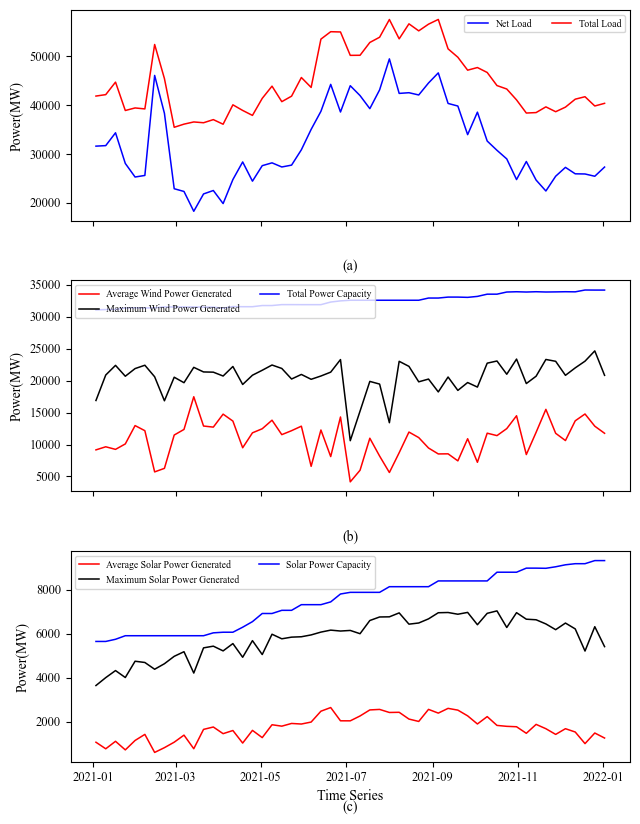

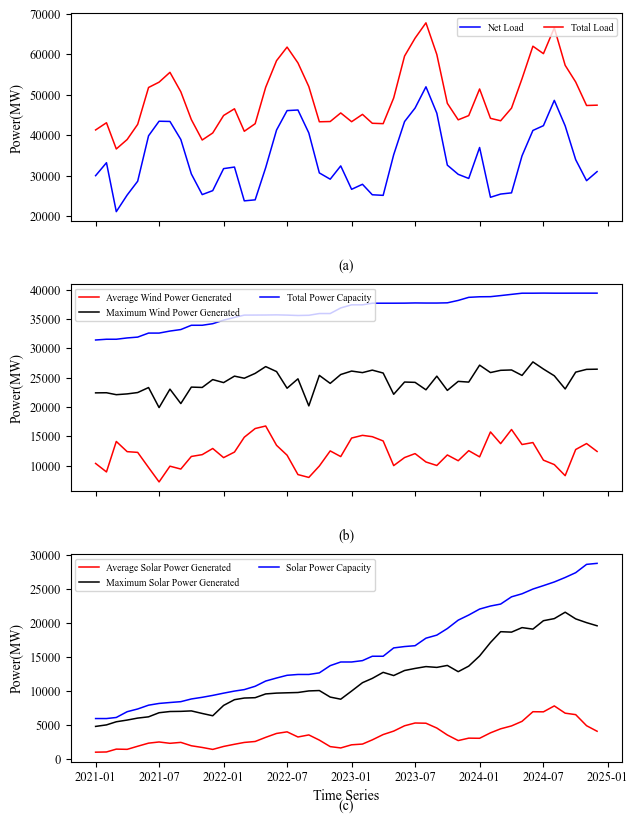

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from pathlib import Path

# =========================
# 1. File paths
# =========================
def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "Data Download").is_dir() and (candidate / "FCNN Direct Method").is_dir():
            return candidate
    raise FileNotFoundError("Cannot locate the repository root.")


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "Data Download"

files = [
    DATA_DIR / "ERCOT_2021_Hourly_WindSolar_Output.xlsx",
    DATA_DIR / "ERCOT_2022_Hourly_WindSolar_Output.xlsx",
    DATA_DIR / "ERCOT_2023_Hourly_WindSolar_Output.xlsx",
    DATA_DIR / "ERCOT_2024_Hourly_WindSolar_Output.xlsx",
]

# =========================
# 2. Helper functions
# =========================
def pick_time_col(df):
    """Handle different time column names across years."""
    for col in ["Time (Hour-Ending)", "Time", "Time.1"]:
        if col in df.columns:
            return col
    for col in df.columns:
        if "time" in str(col).lower():
            return col
    raise ValueError("No valid time column found.")


def read_one_year(file_path):
    """Read one ERCOT yearly file and merge wind/solar sheets."""
    wind = pd.read_excel(file_path, sheet_name="Wind Data")
    solar = pd.read_excel(file_path, sheet_name="Solar Data")

    wind_time_col = pick_time_col(wind)
    solar_time_col = pick_time_col(solar)

    wind_df = wind[
        [wind_time_col, "ERCOT.LOAD", "ERCOT.WIND.GEN", "Total Wind Installed, MW"]
    ].copy()

    wind_df = wind_df.rename(columns={
        wind_time_col: "timestamp",
        "ERCOT.LOAD": "total_load",
        "ERCOT.WIND.GEN": "wind_gen",
        "Total Wind Installed, MW": "wind_capacity",
    })

    solar_df = solar[
        [solar_time_col, "ERCOT.PVGR.GEN", "Total Solar Installed, MW"]
    ].copy()

    solar_df = solar_df.rename(columns={
        solar_time_col: "timestamp",
        "ERCOT.PVGR.GEN": "solar_gen",
        "Total Solar Installed, MW": "solar_capacity",
    })

    wind_df["timestamp"] = pd.to_datetime(wind_df["timestamp"])
    solar_df["timestamp"] = pd.to_datetime(solar_df["timestamp"])

    df = pd.merge(wind_df, solar_df, on="timestamp", how="inner")

    value_cols = [
        "total_load",
        "wind_gen",
        "wind_capacity",
        "solar_gen",
        "solar_capacity",
    ]

    for col in value_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["net_load"] = df["total_load"] - df["wind_gen"] - df["solar_gen"]

    df = df.dropna(subset=value_cols + ["net_load"])
    df = df.drop_duplicates(subset=["timestamp"])
    df = df.sort_values("timestamp")

    return df


def aggregate_data(df, freq):
    """
    freq = 'W'  for weekly aggregation
    freq = 'MS' for monthly aggregation
    """
    agg = (
        df.set_index("timestamp")
          .resample(freq)
          .agg({
              "net_load": "mean",
              "total_load": "mean",
              "wind_gen": ["mean", "max"],
              "wind_capacity": "max",
              "solar_gen": ["mean", "max"],
              "solar_capacity": "max",
          })
    )

    agg.columns = [
        "net_load_avg",
        "total_load_avg",
        "wind_avg",
        "wind_max",
        "wind_capacity",
        "solar_avg",
        "solar_max",
        "solar_capacity",
    ]

    return agg.dropna()


def set_font():
    """Use Times New Roman if available; otherwise use default serif."""
    available_fonts = {f.name for f in font_manager.fontManager.ttflist}
    if "Times New Roman" in available_fonts:
        plt.rcParams["font.family"] = "Times New Roman"
    else:
        plt.rcParams["font.family"] = "serif"

    plt.rcParams["font.size"] = 10


def plot_three_panels(agg, save_path, tick_interval_months=2):
    set_font()

    fig, axes = plt.subplots(
        3, 1,
        figsize=(6.5, 8.3),
        sharex=True
    )

    # -------------------------
    # (a) Net load and total load
    # -------------------------
    axes[0].plot(
        agg.index, agg["net_load_avg"],
        color="blue", linewidth=1.1, label="Net Load"
    )
    axes[0].plot(
        agg.index, agg["total_load_avg"],
        color="red", linewidth=1.1, label="Total Load"
    )
    axes[0].set_ylabel("Power(MW)")
    axes[0].legend(loc="upper right", fontsize=7, ncol=2, frameon=True)

    # -------------------------
    # (b) Wind generation and capacity
    # -------------------------
    axes[1].plot(
        agg.index, agg["wind_avg"],
        color="red", linewidth=1.1, label="Average Wind Power Generated"
    )
    axes[1].plot(
        agg.index, agg["wind_max"],
        color="black", linewidth=1.1, label="Maximum Wind Power Generated"
    )
    axes[1].plot(
        agg.index, agg["wind_capacity"],
        color="blue", linewidth=1.1, label="Total Power Capacity"
    )
    axes[1].set_ylabel("Power(MW)")
    axes[1].legend(loc="upper left", fontsize=7, ncol=2, frameon=True)

    # -------------------------
    # (c) Solar generation and capacity
    # -------------------------
    axes[2].plot(
        agg.index, agg["solar_avg"],
        color="red", linewidth=1.1, label="Average Solar Power Generated"
    )
    axes[2].plot(
        agg.index, agg["solar_max"],
        color="black", linewidth=1.1, label="Maximum Solar Power Generated"
    )
    axes[2].plot(
        agg.index, agg["solar_capacity"],
        color="blue", linewidth=1.1, label="Solar Power Capacity"
    )
    axes[2].set_ylabel("Power(MW)")
    axes[2].set_xlabel("Time Series")
    axes[2].legend(loc="upper left", fontsize=7, ncol=2, frameon=True)

    # Panel labels
    for ax, label in zip(axes, ["(a)", "(b)", "(c)"]):
        ax.text(
            0.5, -0.18, label,
            transform=ax.transAxes,
            ha="center", va="top",
            fontsize=10
        )
        ax.grid(False)
        ax.tick_params(axis="both", labelsize=9)

    # X-axis format
    axes[-1].xaxis.set_major_locator(
        mdates.MonthLocator(interval=tick_interval_months)
    )
    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    fig.tight_layout(h_pad=0.8)
    fig.savefig(save_path, dpi=600, bbox_inches="tight")
    plt.show()


# =========================
# 3. Read all data
# =========================
all_data = pd.concat(
    [read_one_year(file) for file in files],
    ignore_index=True
)

all_data = all_data.drop_duplicates(subset=["timestamp"])
all_data = all_data.sort_values("timestamp")

# Avoid creating a partial January 2025 monthly point
all_data = all_data[
    (all_data["timestamp"] >= "2021-01-01") &
    (all_data["timestamp"] < "2025-01-01")
]

# =========================
# 4. Fig. 1: Weekly resolution, 2021 only
# =========================
data_2021 = all_data[
    (all_data["timestamp"] >= "2021-01-01") &
    (all_data["timestamp"] < "2022-01-01")
]

weekly_2021 = aggregate_data(data_2021, freq="W")

plot_three_panels(
    weekly_2021,
    save_path=DATA_DIR / "Fig1_weekly_resolution.png",
    tick_interval_months=2
)

# =========================
# 5. Fig. 2: Monthly resolution, 2021-2024
# =========================
monthly_2021_2024 = aggregate_data(all_data, freq="MS")

plot_three_panels(
    monthly_2021_2024,
    save_path=DATA_DIR / "Fig2_monthly_resolution.png",
    tick_interval_months=6
)

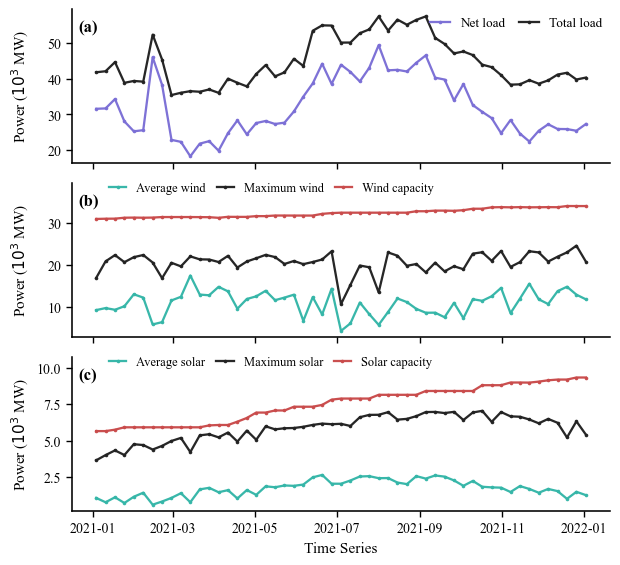

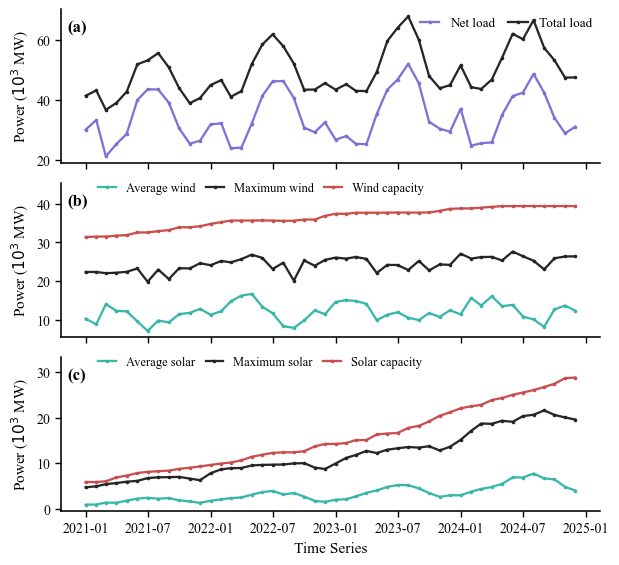

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import font_manager
from pathlib import Path


# ============================================================
# 1. File paths
# ============================================================
def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "Data Download").is_dir() and (candidate / "FCNN Direct Method").is_dir():
            return candidate
    raise FileNotFoundError("Cannot locate the repository root.")


PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "Data Download"

files = [
    DATA_DIR / "ERCOT_2021_Hourly_WindSolar_Output.xlsx",
    DATA_DIR / "ERCOT_2022_Hourly_WindSolar_Output.xlsx",
    DATA_DIR / "ERCOT_2023_Hourly_WindSolar_Output.xlsx",
    DATA_DIR / "ERCOT_2024_Hourly_WindSolar_Output.xlsx",
]


# ============================================================
# 2. Data reading functions
# ============================================================
def pick_time_col(df):
    for col in ["Time (Hour-Ending)", "Time", "Time.1"]:
        if col in df.columns:
            return col

    for col in df.columns:
        if "time" in str(col).lower():
            return col

    raise ValueError("No valid time column found.")


def read_one_year(file_path):
    wind = pd.read_excel(file_path, sheet_name="Wind Data")
    solar = pd.read_excel(file_path, sheet_name="Solar Data")

    wind_time_col = pick_time_col(wind)
    solar_time_col = pick_time_col(solar)

    wind_df = wind[
        [
            wind_time_col,
            "ERCOT.LOAD",
            "ERCOT.WIND.GEN",
            "Total Wind Installed, MW",
        ]
    ].copy()

    wind_df = wind_df.rename(
        columns={
            wind_time_col: "timestamp",
            "ERCOT.LOAD": "total_load",
            "ERCOT.WIND.GEN": "wind_gen",
            "Total Wind Installed, MW": "wind_capacity",
        }
    )

    solar_df = solar[
        [
            solar_time_col,
            "ERCOT.PVGR.GEN",
            "Total Solar Installed, MW",
        ]
    ].copy()

    solar_df = solar_df.rename(
        columns={
            solar_time_col: "timestamp",
            "ERCOT.PVGR.GEN": "solar_gen",
            "Total Solar Installed, MW": "solar_capacity",
        }
    )

    wind_df["timestamp"] = pd.to_datetime(wind_df["timestamp"])
    solar_df["timestamp"] = pd.to_datetime(solar_df["timestamp"])

    df = pd.merge(wind_df, solar_df, on="timestamp", how="inner")

    value_cols = [
        "total_load",
        "wind_gen",
        "wind_capacity",
        "solar_gen",
        "solar_capacity",
    ]

    for col in value_cols:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    df["net_load"] = df["total_load"] - df["wind_gen"] - df["solar_gen"]

    df = df.dropna(subset=value_cols + ["net_load"])
    df = df.drop_duplicates(subset=["timestamp"])
    df = df.sort_values("timestamp")

    return df


# ============================================================
# 3. Aggregation function
# ============================================================
def aggregate_data(df, freq):
    """
    freq = "W"  for weekly aggregation
    freq = "MS" for monthly aggregation
    """
    agg = (
        df.set_index("timestamp")
        .resample(freq)
        .agg(
            {
                "net_load": "mean",
                "total_load": "mean",
                "wind_gen": ["mean", "max"],
                "wind_capacity": "max",
                "solar_gen": ["mean", "max"],
                "solar_capacity": "max",
            }
        )
    )

    agg.columns = [
        "net_load_avg",
        "total_load_avg",
        "wind_avg",
        "wind_max",
        "wind_capacity",
        "solar_avg",
        "solar_max",
        "solar_capacity",
    ]

    return agg.dropna()


# ============================================================
# 4. Nature-style plotting setup
# ============================================================
def set_paper_style():
    """
    Use Times New Roman for IEEE-style consistency.
    """
    available_fonts = {f.name for f in font_manager.fontManager.ttflist}

    if "Times New Roman" in available_fonts:
        plt.rcParams["font.family"] = "Times New Roman"
    else:
        plt.rcParams["font.family"] = "serif"

    plt.rcParams["font.size"] = 10
    plt.rcParams["axes.linewidth"] = 1.15
    plt.rcParams["xtick.major.width"] = 1.0
    plt.rcParams["ytick.major.width"] = 1.0
    plt.rcParams["xtick.major.size"] = 4.0
    plt.rcParams["ytick.major.size"] = 4.0
    plt.rcParams["pdf.fonttype"] = 42
    plt.rcParams["ps.fonttype"] = 42


# restrained Nature-like colors
COLORS = {
    "black": "#222222",
    "purple": "#7B6FD6",
    "teal": "#35B6A8",
    "red": "#C94B4B",
}


def plot_three_panels_nature(
    agg,
    save_path,
    tick_interval_months=2,
    figsize=(6.3, 5.7),
    dpi=600,
):
    set_paper_style()

    fig, axes = plt.subplots(
        3,
        1,
        figsize=figsize,
        sharex=True,
        gridspec_kw={"hspace": 0.13},
    )

    # Convert MW to 10^3 MW
    plot_df = agg.copy()
    scale_cols = [
        "net_load_avg",
        "total_load_avg",
        "wind_avg",
        "wind_max",
        "wind_capacity",
        "solar_avg",
        "solar_max",
        "solar_capacity",
    ]
    plot_df[scale_cols] = plot_df[scale_cols] / 1000.0

    line_kw = dict(
        linewidth=1.65,
        marker="o",
        markersize=2.6,
        markeredgewidth=0,
        alpha=0.98,
    )

    # ========================================================
    # (a) Net load and total load
    # ========================================================
    axes[0].plot(
        plot_df.index,
        plot_df["net_load_avg"],
        color=COLORS["purple"],
        label="Net load",
        **line_kw,
    )

    axes[0].plot(
        plot_df.index,
        plot_df["total_load_avg"],
        color=COLORS["black"],
        label="Total load",
        **line_kw,
    )

    # ========================================================
    # (b) Wind generation and capacity
    # ========================================================
    axes[1].plot(
        plot_df.index,
        plot_df["wind_avg"],
        color=COLORS["teal"],
        label="Average wind",
        **line_kw,
    )

    axes[1].plot(
        plot_df.index,
        plot_df["wind_max"],
        color=COLORS["black"],
        label="Maximum wind",
        **line_kw,
    )

    axes[1].plot(
        plot_df.index,
        plot_df["wind_capacity"],
        color=COLORS["red"],
        label="Wind capacity",
        **line_kw,
    )

    # Leave extra headroom in panel (b) so the legend does not overlap the red capacity curve.
    ymin_b, ymax_b = axes[1].get_ylim()
    axes[1].set_ylim(ymin_b, ymax_b + 0.12 * (ymax_b - ymin_b))

    # ========================================================
    # (c) Solar generation and capacity
    # ========================================================
    axes[2].plot(
        plot_df.index,
        plot_df["solar_avg"],
        color=COLORS["teal"],
        label="Average solar",
        **line_kw,
    )

    axes[2].plot(
        plot_df.index,
        plot_df["solar_max"],
        color=COLORS["black"],
        label="Maximum solar",
        **line_kw,
    )

    axes[2].plot(
        plot_df.index,
        plot_df["solar_capacity"],
        color=COLORS["red"],
        label="Solar capacity",
        **line_kw,
    )

    ymin_c, ymax_c = axes[2].get_ylim()
    axes[2].set_ylim(ymin_c, ymax_c + 0.10 * (ymax_c - ymin_c))

    # ========================================================
    # Axis formatting
    # ========================================================
    panel_labels = ["(a)", "(b)", "(c)"]

    for ax, panel_label in zip(axes, panel_labels):
        ax.set_ylabel(r"Power ($10^3$ MW)", fontsize=11)

        ax.text(
            0.012,
            0.93,
            panel_label,
            transform=ax.transAxes,
            fontsize=12,
            fontweight="bold",
            ha="left",
            va="top",
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.tick_params(
            axis="both",
            labelsize=10,
            direction="out",
        )

        ax.grid(False)

    axes[2].set_xlabel("Time Series", fontsize=11)

    # ========================================================
    # Legends
    # ========================================================
    # Panel (a) has only two curves, so the upper-right legend remains uncluttered.
    axes[0].legend(
        loc="upper right",
        fontsize=9.5,
        frameon=False,
        ncol=2,
        handlelength=1.5,
        columnspacing=1.0,
        borderaxespad=0.2,
    )

    # Place the panel (b) legend above the axes to avoid the wind-capacity curve.
    axes[1].legend(
        loc="upper left",
        bbox_to_anchor=(0.06, 1.04),
        fontsize=9.0,
        frameon=False,
        ncol=3,
        handlelength=1.4,
        columnspacing=0.85,
        borderaxespad=0.0,
    )

    # Place the panel (c) legend above the axes for a consistent layout.
    axes[2].legend(
        loc="upper left",
        bbox_to_anchor=(0.06, 1.04),
        fontsize=9.0,
        frameon=False,
        ncol=3,
        handlelength=1.4,
        columnspacing=0.85,
        borderaxespad=0.0,
    )

    # ========================================================
    # X-axis formatting
    # ========================================================
    axes[-1].xaxis.set_major_locator(
        mdates.MonthLocator(interval=tick_interval_months)
    )
    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%m")
    )

    for label in axes[-1].get_xticklabels():
        label.set_rotation(0)
        label.set_ha("center")

    fig.align_ylabels(axes)

    plt.subplots_adjust(
        left=0.13,
        right=0.985,
        top=0.985,
        bottom=0.105,
        hspace=0.13,
    )

    fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
    fig.savefig(str(save_path).replace(".png", ".pdf"), bbox_inches="tight")
    plt.show()


# ============================================================
# 5. Read all data
# ============================================================
all_data = pd.concat(
    [read_one_year(file) for file in files],
    ignore_index=True,
)

all_data = all_data.drop_duplicates(subset=["timestamp"])
all_data = all_data.sort_values("timestamp")

all_data = all_data[
    (all_data["timestamp"] >= "2021-01-01")
    & (all_data["timestamp"] < "2025-01-01")
]


# ============================================================
# 6. Fig. 1: Weekly resolution, 2021 only
# ============================================================
data_2021 = all_data[
    (all_data["timestamp"] >= "2021-01-01")
    & (all_data["timestamp"] < "2022-01-01")
]

weekly_2021 = aggregate_data(data_2021, freq="W")

plot_three_panels_nature(
    weekly_2021,
    save_path=DATA_DIR / "Fig1_weekly_resolution_nature_style.png",
    tick_interval_months=2,
    figsize=(6.3, 5.7),
)


# ============================================================
# 7. Fig. 2: Monthly resolution, 2021-2024
# ============================================================
monthly_2021_2024 = aggregate_data(all_data, freq="MS")

plot_three_panels_nature(
    monthly_2021_2024,
    save_path=DATA_DIR / "Fig2_monthly_resolution_nature_style.png",
    tick_interval_months=6,
    figsize=(6.3, 5.7),
)